# Outlier Detection & Treatment

This notebook is the third step in the data-preparation pipeline, following EDA and missing-value treatment. Its purpose is to identify and handle **outliers** which are data points that deviate significantly from the majority of observations. Outliers can arise from data entry errors, genuinely rare properties or scraping artifacts.

**Why outlier treatment matters:** Regression models are sensitive to extreme values. A single apartment listed at 10× the typical rent can pull the regression line upward, worsening predictions for the vast majority of normal apartments. By capping or removing these extremes, we improve the model's ability to learn the underlying pattern that governs typical rents.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats


## Loading the Data & Inspecting Summary Statistics

We load `spitogatos_no_missing.csv`, the output of the previous notebook, and immediately review the summary statistics with `.describe().T`. This gives us a quick numerical overview of each feature's range, central tendency, and spread. Extreme minimum or maximum values (e.g., an `areaSqm` of 1,000+ sqm or a `price` far above the 75th percentile) are early hints that outliers are present.


In [2]:
df = pd.read_csv('spitogatos_no_missing.csv')
df.head()


,listingId,airConditioning,alarm,areaSqm,balcony,bathrooms,closedParkingSpots,elevator,energyClass,fireplace,...,pool,price,pricePerSqm,propertyType,renovationYear,rooms,solarHeater,storage,view,yearBuilt
0,20304396,True,False,47,False,1.0,0.0,True,C,False,...,False,600,12.77,apartment,2026.0,1.0,False,False,True,1975.0
1,19956518,True,False,25,False,1.0,0.0,True,B,False,...,False,530,21.20,apartment,2023.0,1.0,False,False,True,1982.0
2,18383741,False,False,60,False,1.0,0.0,True,D,False,...,False,510,8.50,apartment,NaN,1.0,False,False,True,1978.0
3,20242029,True,False,60,False,1.0,0.0,True,F,False,...,False,330,5.50,apartment,NaN,1.0,False,False,True,1978.0
4,20055845,True,False,75,False,1.0,0.0,True,C,False,...,False,620,8.27,apartment,NaN,2.0,False,False,True,1981.0


In [3]:
df.describe().T


,count,mean,std,min,25%,50%,75%,max
listingId,2472.0,1.947960e+07,2.116038e+06,782706.0,1.979025e+07,20148959.00,20294254.5,20383704.0
areaSqm,2472.0,5.508212e+01,2.994053e+01,15.0,3.500000e+01,47.00,69.0,450.0
bathrooms,2472.0,1.031958e+00,1.913501e-01,1.0,1.000000e+00,1.00,1.0,5.0
closedParkingSpots,2472.0,1.618123e-03,4.020147e-02,0.0,0.000000e+00,0.00,0.0,1.0
floor,2472.0,7.043285e+00,2.519079e+00,0.0,6.000000e+00,7.00,9.0,15.0
kitchens,2472.0,1.001618e+00,4.020147e-02,1.0,1.000000e+00,1.00,1.0,2.0
livingRooms,2472.0,1.005259e+00,7.773512e-02,1.0,1.000000e+00,1.00,1.0,3.0
openParkingSpots,2472.0,3.276699e-02,1.825511e-01,0.0,0.000000e+00,0.00,0.0,2.0
price,2472.0,6.554753e+02,3.098590e+03,190.0,4.500000e+02,550.00,650.0,154000.0
pricePerSqm,2472.0,1.311266e+01,6.183045e+01,1.0,8.967500e+00,11.31,14.2,3080.0


## Visual Outlier Detection with Box Plots

Box plots provide a concise visual summary of a feature's distribution. The **box** spans the interquartile range (IQR, from Q1 to Q3), the **line inside the box** marks the median, and the **whiskers** extend to 1.5× IQR beyond the box. Any points plotted beyond the whiskers are considered **potential outliers** by the standard box-plot rule.

We plot box plots for four key numerical features: `areaSqm`, `floor`, `price`, and `yearBuilt`. These were identified during EDA as the most relevant continuous predictors and are also the ones most likely to contain extreme values that could distort a regression model.


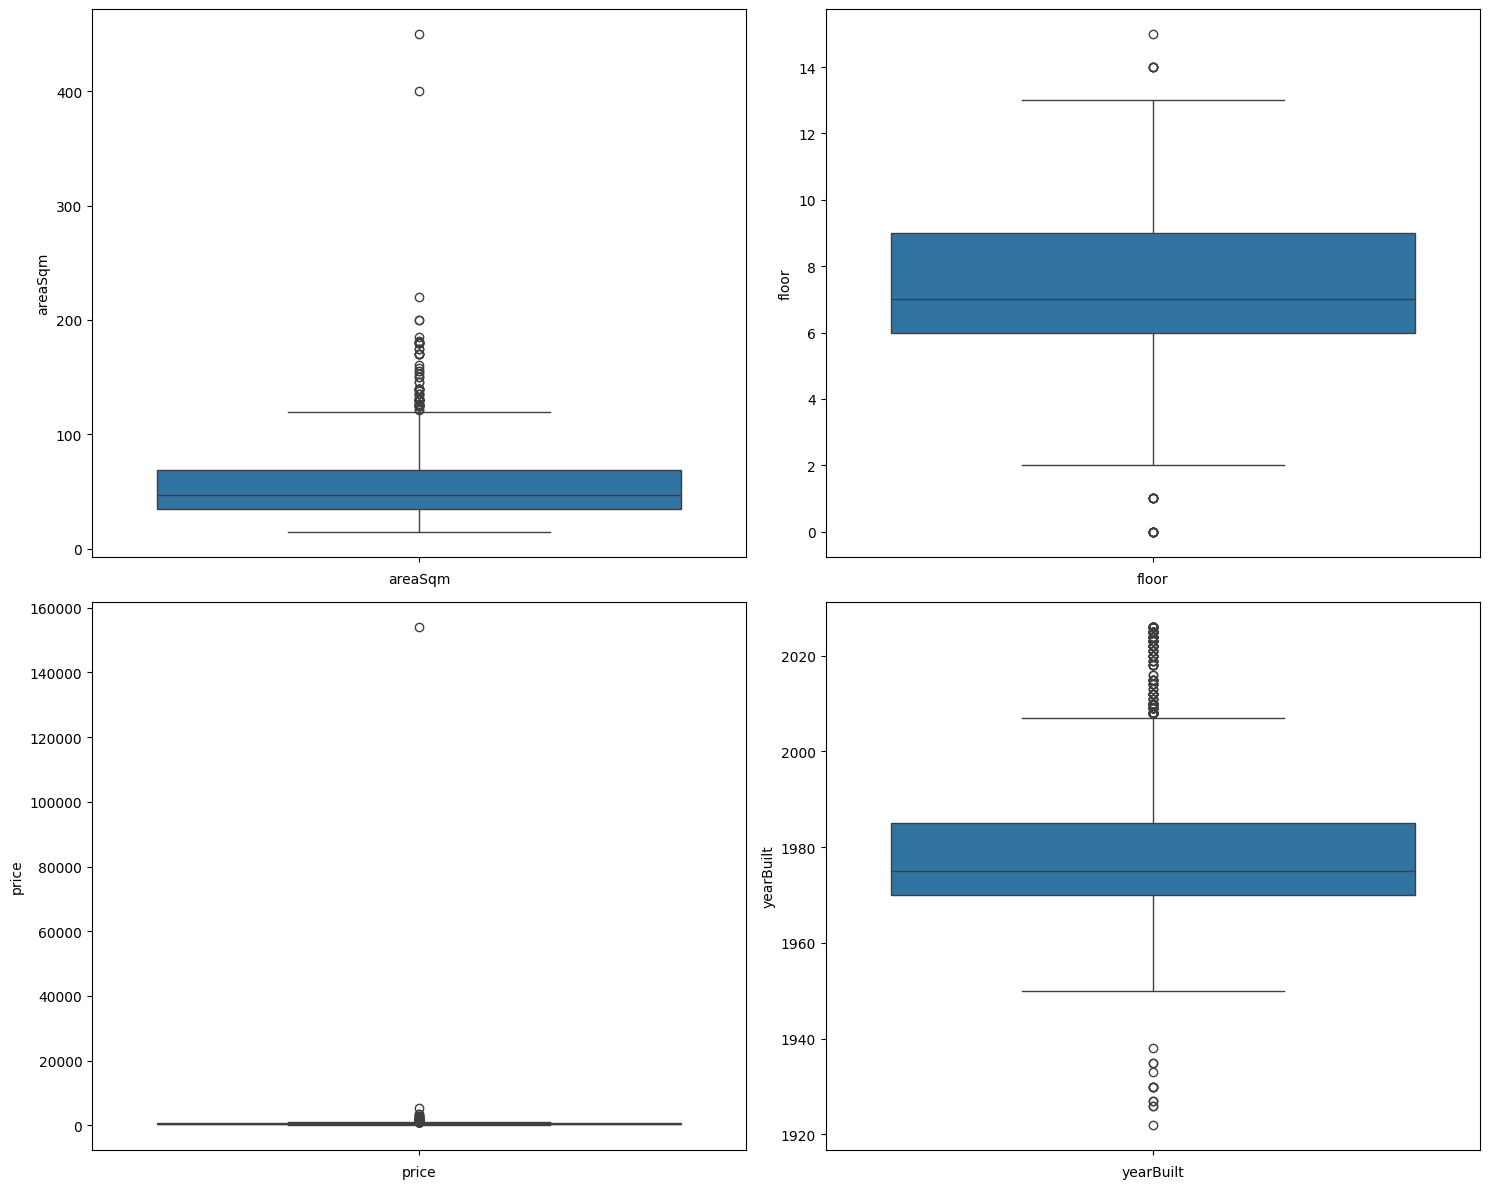

In [4]:
features = ['areaSqm', 'floor', 'price', 'yearBuilt']
plt.figure(figsize=(15,12))

for i, col in enumerate(features):
  plt.subplot(2, 2, i+1)
  sns.boxplot(df[col])
  plt.xlabel(col)

plt.tight_layout()
plt.show()


## Outlier Detection Strategy

We can notice the presence of outliers in our dataset so we can deal with this problem using the **clipping method**. In this method, we set a cap on our outliers data, which means that if a value is higher than or lower than a certain threshold, all values will be considered outliers. This method replaces values that fall outside of a specified range with either the minimum or maximum value within that range.

### Why clipping over removal?

An alternative to clipping is to simply **drop** outlier rows. However, dropping rows reduces the training set size and can introduce bias if the outliers are not truly erroneous (e.g., a genuinely large apartment). Clipping preserves every row while limiting the influence of extreme values. The outlier's information (e.g., "this apartment is above average") is retained, but its magnitude is capped to a reasonable threshold.


## Quantifying Outliers

Before choosing thresholds, we quantify the outlier problem for each feature using three complementary criteria:

- **95th percentile (95p):** A common benchmark. Values above this point represent the top 5% of the distribution.
- **3 standard deviations (3σ):** Based on the Z-score. In a normal distribution, ~99.7% of data falls within 3σ of the mean, so values beyond this are statistically unlikely.
- **99th percentile (99p):** A more permissive threshold. Only the top 1% of values are flagged.

By printing all three for each feature, we can make an informed decision about which threshold to use. A feature with many values beyond 3σ but few beyond the 99th percentile may be best handled with a 99p clip.


In [5]:
def detect_outliers(feature):
    outliers = []
    data = df[feature]
    mean = np.mean(data)
    std = np.std(data)
    
    for x in data:
        z = (x-mean)/std
        if np.abs(z) > 3:
            outliers.append(x)
            
    print(f"Outliers for {feature}\n")
    print(f"95p: {data.quantile(0.95)}/{len([i for i in data if i > data.quantile(0.95)])} values exceed that")
    print(f"3std: {mean+3*std}/{len(outliers)} values exceed that")
    print(f"99p: {data.quantile(0.99)}/{len([i for i in data if i > data.quantile(0.99)])} values exceed that\n")


In [6]:
for feature in features:
    detect_outliers(feature)


Outliers for areaSqm

95p: 110.0/121 values exceed that
3std: 144.88555252706237/29 values exceed that
99p: 150.8699999999999/25 values exceed that

Outliers for floor

95p: 11.0/106 values exceed that
3std: 14.598992590184022/1 values exceed that
99p: 13.0/5 values exceed that

Outliers for price

95p: 1000.0/112 values exceed that
3std: 9949.365956402358/1 values exceed that
99p: 1800.0/20 values exceed that

Outliers for yearBuilt

95p: 2018.0/122 values exceed that
3std: 2030.9663506556697/9 values exceed that
99p: 2026.0/0 values exceed that



## Applying the Clipping Method

Based on the outlier analysis above, we apply clipping to the two features where outliers are most impactful for our prediction task: `areaSqm` and `price`. We use the **99th percentile** as the upper bound. This is a deliberate choice:

- It is more conservative than 3σ, meaning we only cap the most extreme 1% of values.
- It preserves the vast majority of the natural variance in the data.
- For a rental-price prediction model, the exact price of a luxury outlier is less important than correctly predicting prices for the typical apartment.

The `.clip(upper=...)` method replaces any value above the threshold with the threshold value itself. Values below the threshold are left unchanged.


In [7]:
df['areaSqm'] = df['areaSqm'].clip(upper=df['areaSqm'].quantile(0.99))
df['price'] = df['price'].clip(upper=df['price'].quantile(0.99))


## Verifying the Results

After clipping, we re-plot the box plots for `areaSqm` and `price` to visually confirm that the most extreme outliers have been tamed. We also re-print the summary statistics to verify that the maximum values have changed while the overall distribution (mean, std, quartiles) remains reasonable.


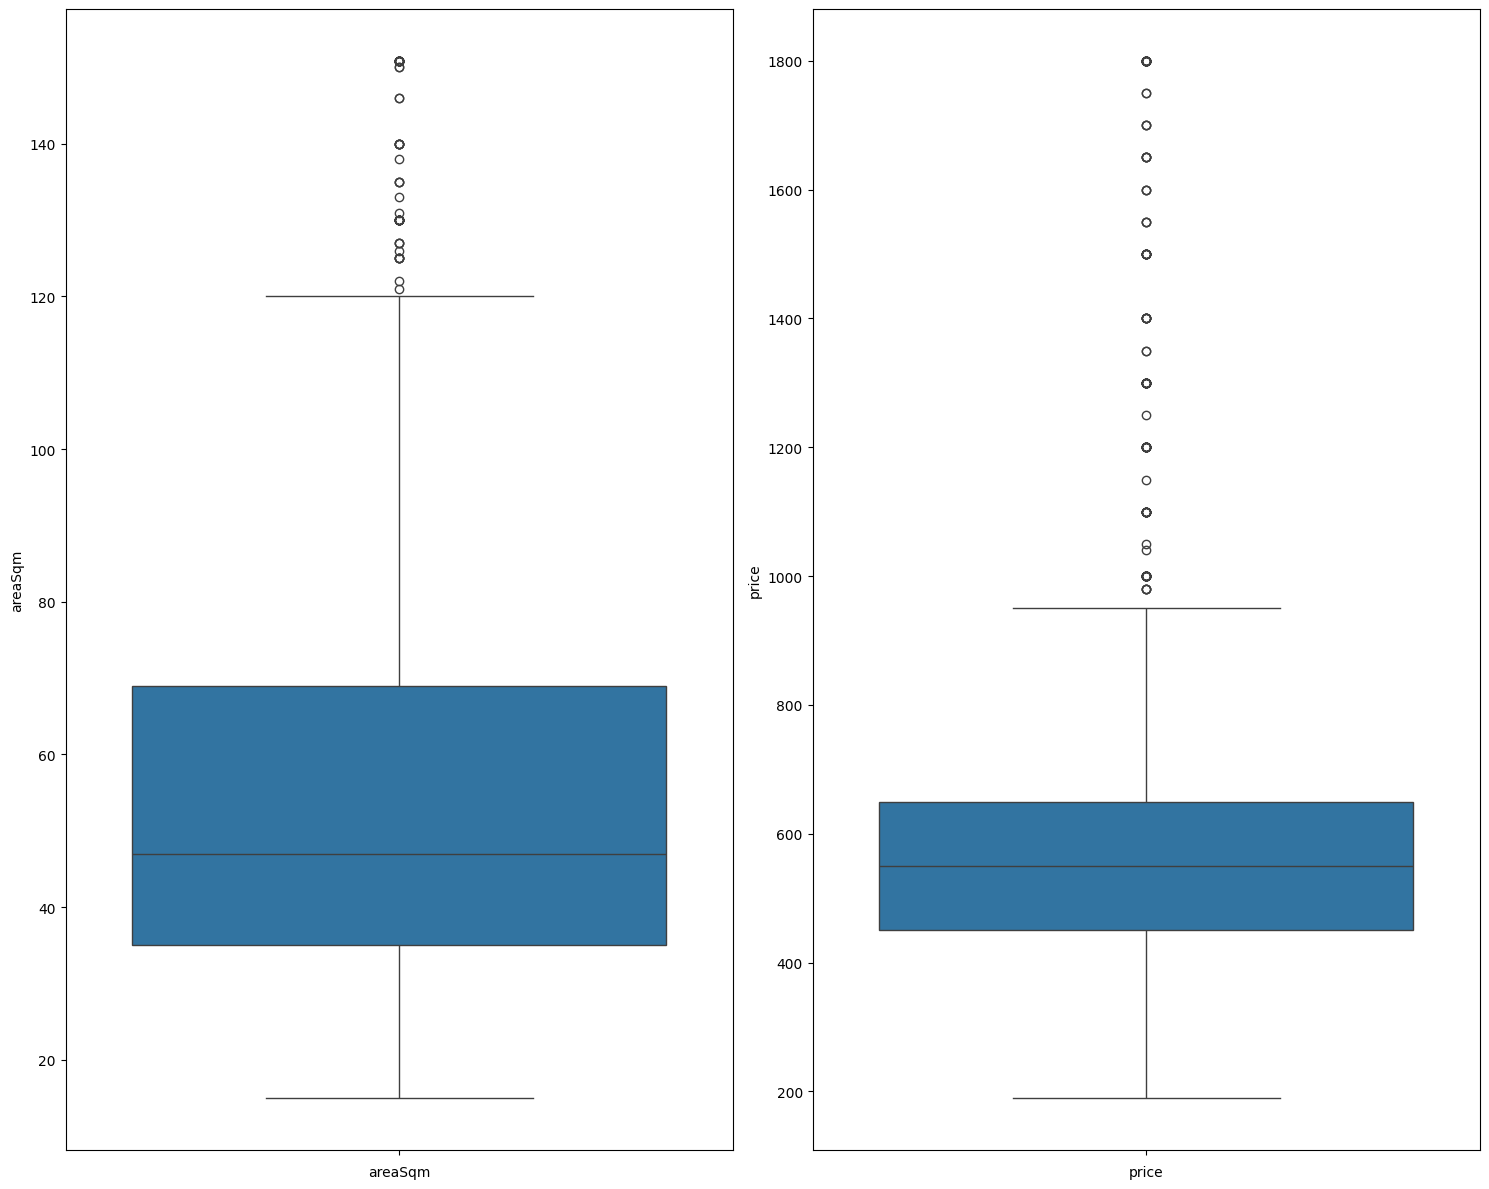

In [8]:
plt.figure(figsize=(15,12))

for i, col in enumerate(['areaSqm', 'price']):
  plt.subplot(1, 2, i+1)
  sns.boxplot(df[col])
  plt.xlabel(col)

plt.tight_layout()
plt.show()


In [9]:
df.describe().T


,count,mean,std,min,25%,50%,75%,max
listingId,2472.0,1.947960e+07,2.116038e+06,782706.0,1.979025e+07,20148959.00,20294254.5,20383704.00
areaSqm,2472.0,5.462571e+01,2.719007e+01,15.0,3.500000e+01,47.00,69.0,150.87
bathrooms,2472.0,1.031958e+00,1.913501e-01,1.0,1.000000e+00,1.00,1.0,5.00
closedParkingSpots,2472.0,1.618123e-03,4.020147e-02,0.0,0.000000e+00,0.00,0.0,1.00
floor,2472.0,7.043285e+00,2.519079e+00,0.0,6.000000e+00,7.00,9.0,15.00
kitchens,2472.0,1.001618e+00,4.020147e-02,1.0,1.000000e+00,1.00,1.0,2.00
livingRooms,2472.0,1.005259e+00,7.773512e-02,1.0,1.000000e+00,1.00,1.0,3.00
openParkingSpots,2472.0,3.276699e-02,1.825511e-01,0.0,0.000000e+00,0.00,0.0,2.00
price,2472.0,5.884648e+02,2.428749e+02,190.0,4.500000e+02,550.00,650.0,1800.00
pricePerSqm,2472.0,1.311266e+01,6.183045e+01,1.0,8.967500e+00,11.31,14.2,3080.00


Comparing the before-and-after `describe()` output, we should see that the maximum values for `areaSqm` and `price` now match their respective 99th percentiles, while the mean and standard deviation have shifted only slightly, confirming that clipping had a targeted effect without distorting the overall distribution.


In [10]:
df.to_csv('spitogatos_no_outliers.csv', index=False)
